# NicheJEPA Tutorial

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 30.06.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

## 1. Setup

### 1.1 Load Libraries 

In [40]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
sys.path.append("../../utils")

In [2]:
import logging
import os
import warnings

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from datasets import load_from_disk
from matplotlib.colors import Normalize
import squidpy as sq

from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_gene_embed,
                       get_average_gene_embed,
                       get_spatial_score,
                       get_emd_distance )

from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(


### 1.2 Configure Paths

In [9]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055'

### 1.3 Define Config

In [10]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [11]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [12]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [13]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [14]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'
sc.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)


In [10]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhb1002-AT15-10b_1p (GBM)

In [12]:
dataset_name = 'xhb1002-AT15-10b_1p'
cell_type_key = 'leiden_log1pnorm_res-1'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/AT15-BRA-4-FO-G1-S24__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad'

In [3]:
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-2.h5ad'


#### 2.1.1 Load Data

In [4]:
adata = sc.read_h5ad(file_path)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


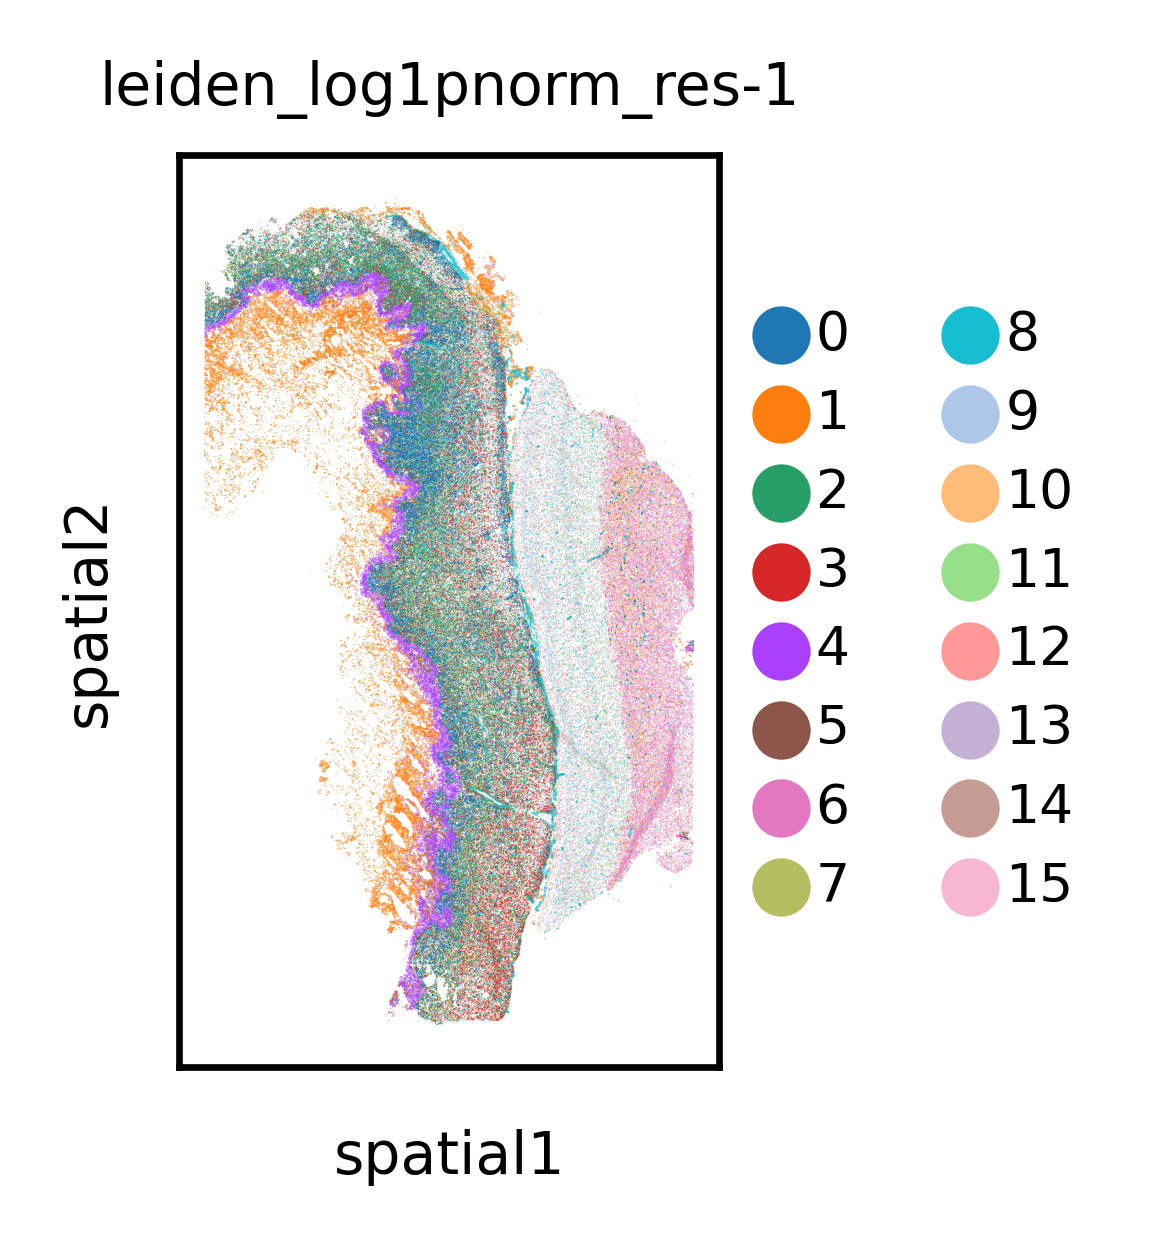

In [13]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


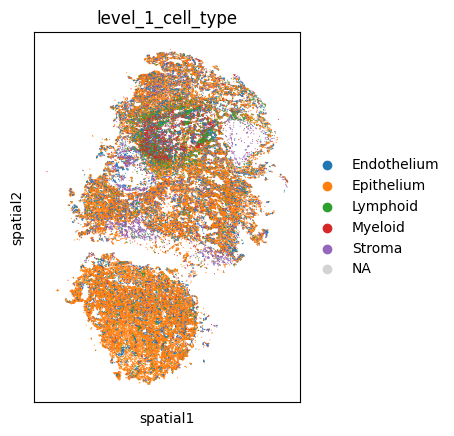

In [5]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

#### 2.1.2 Harmonize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [14]:
adata = harmonize_adata(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           312.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


#### 2.1.3 Tokenize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [ ]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/mv10/nemo_v6/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.


#### 2.1.4 Save Tokenize Data

In [ ]:
num_shards = 32
save_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'

In [ ]:
!mkdir save_dataset_path

In [22]:
dataset.save_to_disk(
            save_dataset_path,
            num_shards=num_shards)

Saving the dataset (0/32 shards):   0%|          | 0/71118 [00:00<?, ? examples/s]

#### 2.1.5 Load Tokenize Data

In [6]:
load_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'
dataset = load_from_disk(load_dataset_path)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

#### 2.1.6 Embed Data

In [18]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

In [19]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
556it [16:24,  1.77s/it]


In [20]:
adata.obsm['cell_emb'] = output_embed['cell_emb']
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']

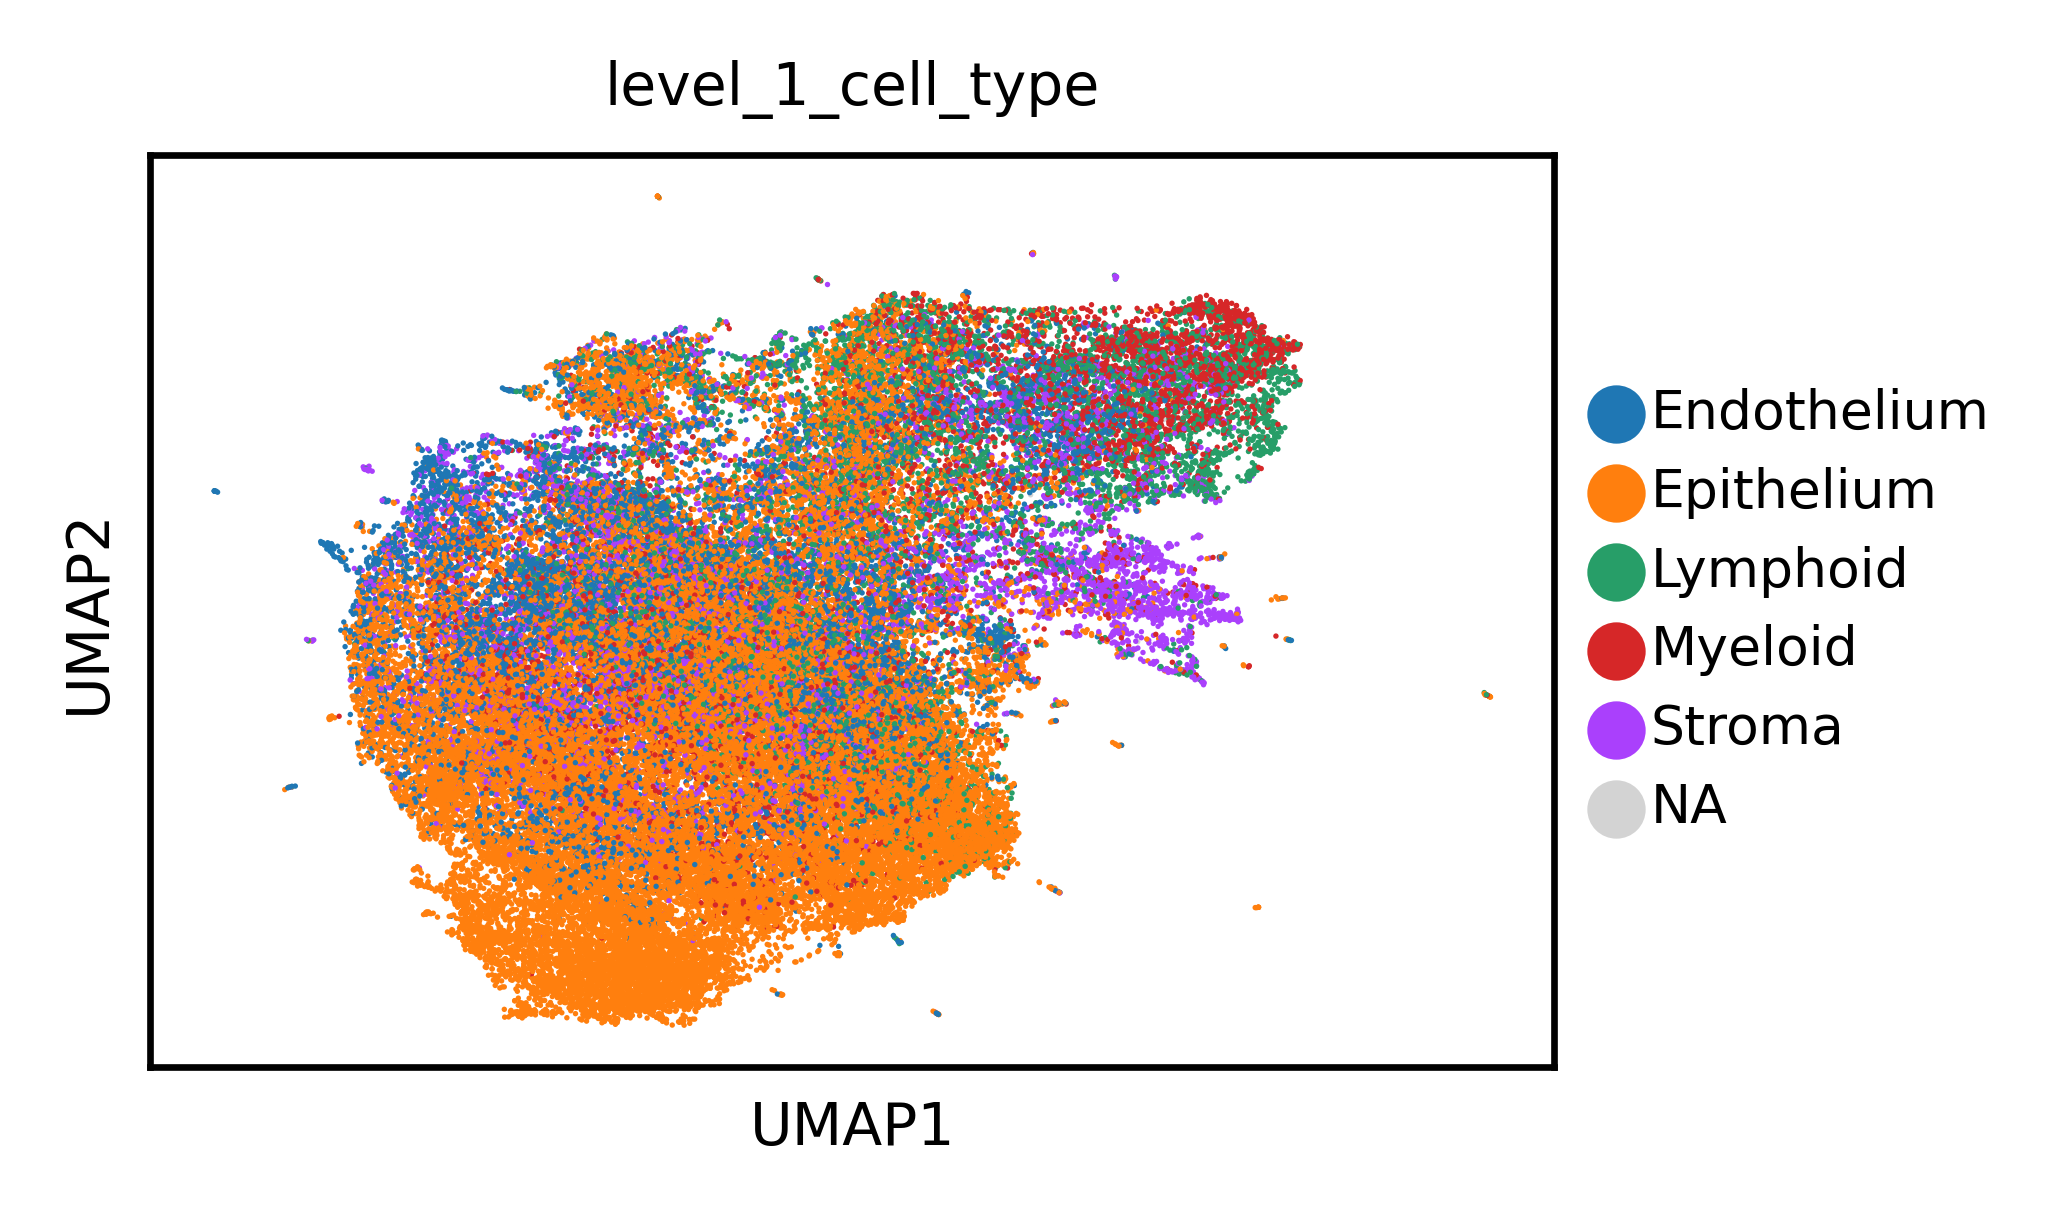

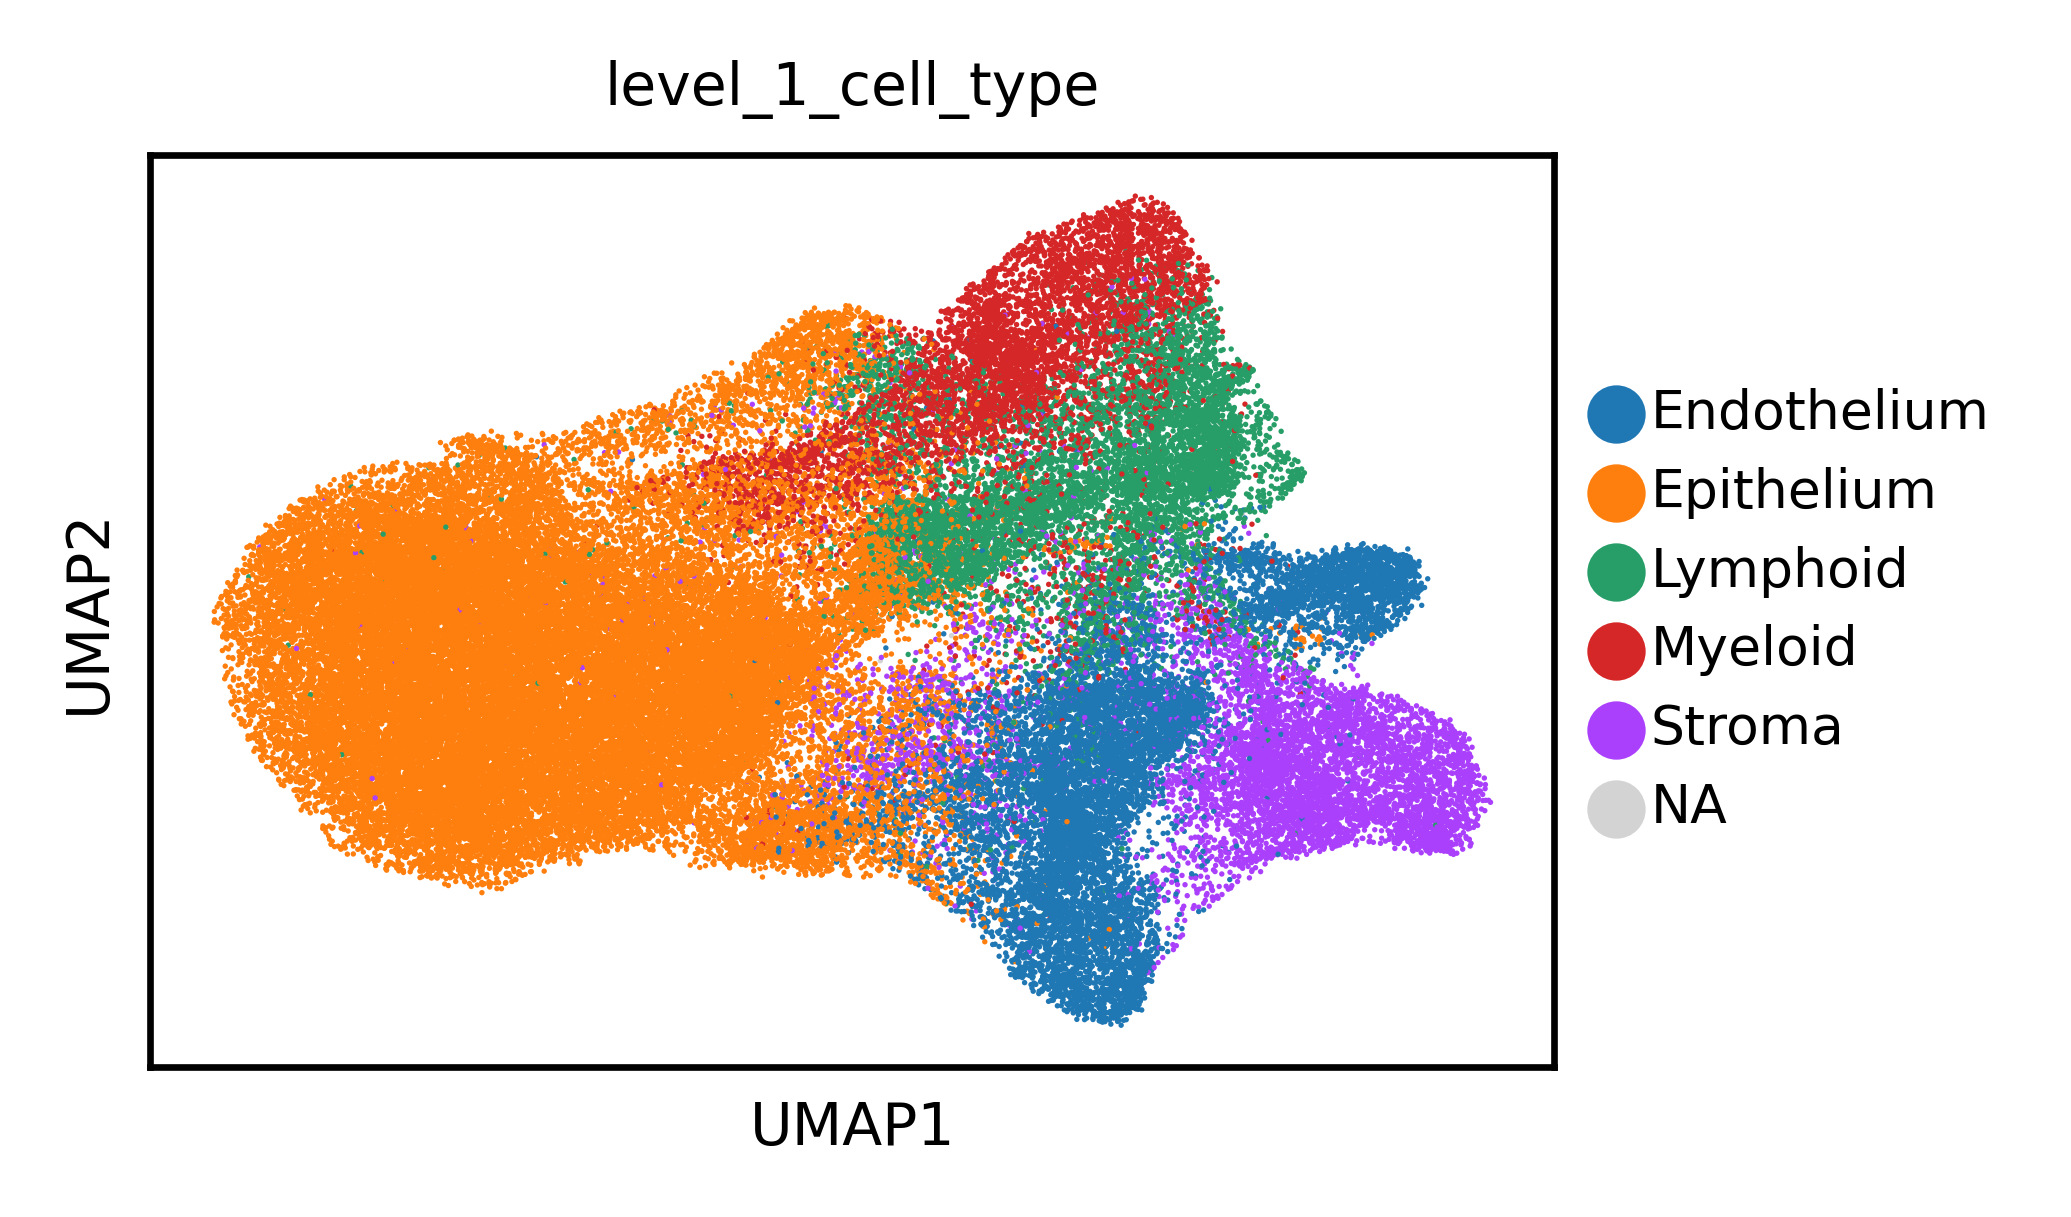

In [30]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')
# Store the neighborhood UMAP with a custom key
adata.obsm['neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')
# Store the cell UMAP with a custom key
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='cell',
           color=label)


#### Niche Identification

In [ ]:
# Set dataset params
batch_key = 'batch'
emb_key = 'neighborhood'
latent_leiden_resolution = 0.2
spot_sizes = [0.3, 30]

latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'


In [ ]:
# Compute UMAP representation for (aggregated) gene embeddings
if F'{emb_key}_connectivities' not in adata.obsp.keys():
    print("Computing sc.pp.neighbors...")
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'{emb_key}_emb_layer_{layer}',
                    key_added=emb_key)
if f'{emb_key}_umap' not in adata.obsm.keys():
    print("Computing sc.tl.umap...")
    sc.tl.umap(adata,
               neighbors_key=emb_key,
               key_added=f'{emb_key}_umap')


In [ ]:
sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
sc.pl.spatial(
    adata,
    color=latent_cluster_key,
    spot_size=0.1,
    save=f'{read_checkpoint.split("-")[1].split(".")[0]}_smb1-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg')

os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_smb1-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg',
          f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_smb1-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg'.replace("show", ""))


#### 2.1.7 get_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [21]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12

In [22]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402']
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402'] # ['all'] * len(perturbed_cell_id)

In [ ]:
output_gene_embed = get_gene_embed( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [37]:
for gene_ens in output_gene_embed.keys():
    adata.obsm[gene_ens] = output_gene_embed[gene_ens]

#### 2.1.8 get_average_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [18]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402']
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402'] # ['all'] * len(perturbed_cell_id)

In [ ]:
output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']


In [ ]:
# 1) Extract raw arrays
gene_emb_name = 'cell_gene_emb_average_per_data'
gene_emb = np.array(adata.uns[gene_emb_name])  # (n_genes, emb_dim)
gene_ids = cell_gene_ensembl_id                  # (n_genes,)

# 2) Remove any gene rows containing NaNs
mask = ~np.isnan(gene_emb).any(axis=1)
gene_emb_clean = gene_emb[mask]
gene_ids_clean = gene_ids[mask]

# 3) Build a small AnnData where each "obs" is one gene
adata_genes = ad.AnnData(
    X=gene_emb_clean,
    obs=pd.DataFrame({'gene_id': gene_ids_clean})
)
adata_genes.obs_names = gene_ids_clean.astype(str)

# 4) Compute a neighborhood graph on the embeddings
sc.pp.neighbors(
    adata_genes,
    use_rep='X',
    n_neighbors=15,
    metric='euclidean'
)

# 5) Run UMAP
sc.tl.umap(
    adata_genes,
    #min_dist=0.5,
    #spread=1.0
)


# 7) (Optional) Quick plot
sc.pl.umap(
    adata_genes,
    title='Gene embedding UMAP',
    show=True
)


In [ ]:
sc.tl.pca(adata_genes, n_comps=2, use_highly_variable=False, svd_solver='arpack')

sc.pl.pca(
    adata_genes,
    components=['1,2'],   # plot PC1 vs PC2
    color=None,
    title='Gene embeddings PCA (PC1 vs PC2)',
    show=True
)


In [ ]:
new_adata = adata_genes
# Store results here
results = []

# Define parameters
knn_values = [5, 10, 15, 20]
resolutions = np.arange(0.1, 1.1, 0.1)  # 0.1 to 1.0

# Loop over each KNN and resolution combination
for knn in knn_values:
    sc.pp.neighbors(new_adata, n_neighbors=knn, use_rep='X')  # use 'X' or other embedding like 'X_pca'
    
    for res in resolutions:
        # Run Leiden clustering
        sc.tl.leiden(new_adata, resolution=res, key_added='leiden_tmp')
        
        # Compute silhouette score
        labels = new_adata.obs['leiden_tmp']
        if len(np.unique(labels)) < 2:
            score = np.nan  # silhouette score not defined for 1 cluster
        else:
            score = silhouette_score(new_adata.obsm['X_pca'], labels)  # you can change to 'X' if no PCA
        
        # Store results
        results.append({
            'knn': knn,
            'resolution': round(res, 2),
            'silhouette_score': score
        })

# Convert results to DataFrame
df = pd.DataFrame(results)
df['combo'] = df['knn'].astype(str) + '_k_' + df['resolution'].astype(str)

# Plot
plt.figure(figsize=(12, 6))
df_sorted = df.sort_values('silhouette_score', ascending=False)
plt.bar(df_sorted['combo'], df_sorted['silhouette_score'], color='skyblue')
plt.xticks(rotation=90)
plt.ylabel("Silhouette Score")
plt.xlabel("KNN_Resolution Combination")
plt.title("Silhouette Score for Different KNN and Leiden Resolution Settings")
plt.tight_layout()
plt.show()


In [ ]:
sc.pp.neighbors(new_adata,n_neighbors=20)
sc.tl.leiden(new_adata,resolution=0.1,key_added='r9')

In [ ]:
sc.pl.umap(new_adata,color='r9',frameon=False)

In [ ]:
# 1) Install gseapy (if not already)
#    !pip install gseapy

# 2) Your input gene list

# 3) Call gseapy.enrichr
#    You can choose any Enrichr library; here are some examples:
# I should create a mapping from gene_id to ens
# from 110 release
libraries = [
    'KEGG_2019_Human',
    'GO_Biological_Process_2021',
    'Reactome_Pathways_2024',
    'MSigDB_Hallmark_2020'
]

# Run ORA for each library
results = {}
for lib in libraries:
    enr = gp.enrichr(
        gene_list = genes,
        gene_sets  = lib,
        outdir     = None,        # don't write files
        cutoff     = 0.05,         # only show terms with adjusted p < 0.05
    )
    # enr.results is a pandas DataFrame
    results[lib] = enr.results

# 4) Inspect top enriched terms for each library
for lib, df in results.items():
    print(f"\n=== Top 5 terms in {lib} ===")
    display(df[['Term','Adjusted P-value','Combined Score']].head(20))


#### 2.1.9 compute_spatial_score
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
# Comment for Mohammad not for you.
# I should add it hardcoded some threshold on the counts for its.
# output to gets back from the get_spatial_score function.
# 

In [23]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402'] 
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402']  # ['all'] * len(perturbed_cell_id)

In [24]:
output_cosine_sim_score = get_spatial_score(dataset=dataset.select(range(5)),
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: COMPUTE THE COSINE SIMILARITY SCORE BETWEEN GENES IN THE CELL AND GENES IN THE NEIGHBORHOOD.


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


1it [00:00,  1.48it/s]


In [27]:
gene_pair_score = output_cosine_sim_score['cos_sim_neighborhood'] / output_cosine_sim_score['cos_sim_cell']

In [28]:
gene_pair_score

array([[0.6275265 , 0.37568954],
       [0.4586091 , 0.5969032 ]], dtype=float32)

In [ ]:
# this is gene_score
# 1) grab the cos_sim matrix and its diagonal
cos_sim = gene_pair_score          # shape (883, 883)
diag    = np.diag(cos_sim)              # length 883

# 2) find which diagonal entries are not NaN
valid_mask = ~np.isnan(diag)
valid_idx  = np.where(valid_mask)[0]    # array of integer positions

# 3) fetch the corresponding gene IDs
#    assuming adata.uns['cell_gene_ids'] is a list/array of length 883
gene_ids   = np.array(adata.uns['cell_gene_ids'])
valid_genes  = gene_ids[valid_idx]      # gene IDs for non‐NaN diagonals
valid_values = diag[valid_mask]         # their cosine‐similarity values

# 4) (optional) assemble into a DataFrame for easy viewing
gene_score = pd.DataFrame({
    'gene_token':   valid_genes,
    'cos_sim':   valid_values
})


#### 2.1.10 compute_emd_distance
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [36]:
# each list should at least contain 20 gene each 
# to have score that is meaningful
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402'] 
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402']  # ['all'] * len(perturbed_cell_id)


In [32]:
output_emd_distance = get_emd_distance( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: COMPUTE EMD DISTANCE BETWEEN GENE IN CELL AND NEIGHBORHOOD


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


1it [00:00,  1.65it/s]


In [ ]:
adata.obs['emd_dist'] = output_emd_distance

In [ ]:
# 2) Normalize your data so that 0→0; 0.6→1.0
norm = Normalize(vmin=0.0, vmax=max(output_emd_distance))

# 3) Build the colormap
#cmap = make_thresholded_cmap(base_cmap="plasma", threshold=0.8)

sq.pl.spatial_scatter(
        adata_batch,
        color='emd_dist',
        #cmap=cmap,
        norm=norm,
        shape=None,
        figsize=(10, 8),
        size=1.5,
        title=f"{dataset_name} — batch {batch_id} (EMD distance)",
)
plt.show()

#### 2.1.11 Perturbed Data

In [ ]:
# Define perturbations
perturbed_cell_id = ['1007_batch20_0', '1007_batch20_0', '1007_batch20_1']
perturbed_ensembl_id = ['all', 'all', 'ENSG00000169194'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'foldchange'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, 0.5] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

In [ ]:
perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path)

#### 2.1.12 Embed Perturb Data

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth - 8)
latent_leiden_resolution = 0.2

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata_test = sc.read_h5ad(f'/nfs/team361/dj17/inflow_pertubation/adata_unperturbed_v2.h5ad')
adata_test.obs['cell_id']

# Initialize the column with False
adata.obs['selected'] = False

# Set True for the selected indices
adata.obs.loc[adata.obs.index[selected_indices], 'selected'] = True